# ASL Signs EDA: animating 94k landmark sequences

Live app: [https://swapnil007-curious.github.io/manuvox/](https://swapnil007-curious.github.io/manuvox/) · GitHub: [https://github.com/Swapnil007-Curious/ManuVox](https://github.com/Swapnil007-Curious/ManuVox) · Paper: link coming soon

The Google Isolated Sign Language Recognition data (Kaggle competition `asl-signs`) holds 94,477 short clips of 250 American Sign Language signs by 21 signers, stored as MediaPipe Holistic landmarks instead of video. This notebook animates real sequences as skeletons and measures what matters before you train on them: how signs and signers are spread, how long the sequences are, how often the hands go missing, and which hand does the signing.

Data: the `asl-signs` competition files only (CC BY 4.0). Runs on CPU, about 10 minutes on Kaggle. It is part 1 of 5 in the series behind ManuVox, a browser app that recognises these 250 signs from a webcam.

Contents

1. Setup and data
2. Signs and signers
3. Sequence length
4. Missing hands
5. Which hand signs
6. Signing space and body proportions
7. Skeleton animations
8. What we found

## 1. Setup and data

Every sequence is one parquet file with one row per landmark per frame: 468 face points, 21 points for each hand and 33 pose points, so 543 rows per frame. `x` and `y` are fractions of the video frame's width and height, and a part of the body MediaPipe did not find is NaN. The constants and readers below are shared by all five notebooks in the series.

In [1]:
import json
import math
import os
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from cycler import cycler
from IPython.display import Image, Markdown, display
from matplotlib.colors import LinearSegmentedColormap

# Kaggle paths. The environment variables only matter when the notebook runs outside Kaggle.
INPUT_DIR = Path(os.environ.get("KAGGLE_INPUT_DIR", "/kaggle/input"))
WORK_DIR = Path(os.environ.get("KAGGLE_WORKING_DIR", "/kaggle/working"))
WORK_DIR.mkdir(parents=True, exist_ok=True)
# FAST=1 keeps a few sequences per sign, for testing the notebook end to end on a laptop.
FAST = os.environ.get("MANUVOX_FAST", "0") == "1"
FAST_PER_SIGN = 24  # Sequences per sign in FAST mode (250 signs, so about 6,000 sequences).
SEED = 42  # One seed for every random choice in the notebook.
N_WORKERS = os.cpu_count() or 1  # Kaggle gives 4 CPUs.

random.seed(SEED)
np.random.seed(SEED)

# Plot style: a colour-blind-safe categorical palette (checked for deutan, protan and tritan
# separation), one blue ramp for magnitudes, hairline grids.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, AQUA, YELLOW = PALETTE[:4]
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"]
)
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.prop_cycle": cycler(color=PALETTE),
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlecolor": INK,
        "axes.titlelocation": "left",
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": INK_2,
        "ytick.color": INK_2,
        "legend.frameon": False,
        "figure.dpi": 100,
        "font.size": 10,
    }
)


def takeaway(text):
    """Print the one-line reading of the plot above, written from this run's numbers."""
    display(Markdown(f"Takeaway: {text}"))


def save_cover(fig, name="cover.png"):
    """Save a 1280x720 copy of ``fig`` as the notebook's cover image."""
    fig.set_size_inches(12.8, 7.2)
    fig.savefig(WORK_DIR / name, dpi=100)


print(f"FAST mode: {FAST}; {N_WORKERS} CPUs")
if FAST:
    print(f"FAST is a test run on up to {FAST_PER_SIGN} sequences per sign with short training: "
          "every number below comes from that sample, not from the full data.")

FAST mode: True; 4 CPUs
FAST is a test run on up to 24 sequences per sign with short training: every number below comes from that sample, not from the full data.


In [2]:
import multiprocessing as mp

COMPETITION = "asl-signs"
# Every frame of a sequence file holds 543 rows in this order (checked on a sample below).
BLOCKS = {"face": 468, "left_hand": 21, "pose": 33, "right_hand": 21}
ROWS_PER_FRAME = sum(BLOCKS.values())
LEFT_START, POSE_START, RIGHT_START = 468, 489, 522
# Selected landmarks: left hand 0-20, right hand 0-20, then pose 0-16 (nose, eyes, ears, mouth
# corners, shoulders, elbows, wrists). The face mesh is dropped. L = 59.
POSE_POINTS = list(range(17))
SELECTED = np.r_[
    LEFT_START : LEFT_START + 21, RIGHT_START : RIGHT_START + 21, POSE_START + np.array(POSE_POINTS)
]
N_LANDMARKS = len(SELECTED)
LEFT, RIGHT = slice(0, 21), slice(21, 42)
NOSE, L_SHOULDER, R_SHOULDER, L_WRIST, R_WRIST = (42 + i for i in (0, 11, 12, 15, 16))
# Left/right pose pairs that a mirror swaps (eyes, ears, mouth corners, shoulders, elbows, wrists).
POSE_SWAP_PAIRS = [(1, 4), (2, 5), (3, 6), (7, 8), (9, 10), (11, 12), (13, 14), (15, 16)]
NUM_FRAMES = 32  # Every sequence is resampled to this many frames.
MIN_HAND_FRAMES = 3  # Sequences with fewer frames showing a hand are dropped.
FRAME_DIM = 2 * N_LANDMARKS + 2  # x, y per landmark, then left and right hand presence.


def find_competition_dir(root=INPUT_DIR, name=COMPETITION):
    """Return the folder holding train.csv and the sign map, wherever Kaggle mounts it."""
    for candidate in (root / name, root / "competitions" / name):
        if (candidate / "train.csv").is_file():
            return candidate
    for folder, subfolders, files in os.walk(root, followlinks=True):
        subfolders[:] = [s for s in subfolders if s != "train_landmark_files"]
        if "train.csv" in files and "sign_to_prediction_index_map.json" in files:
            return Path(folder)
    raise FileNotFoundError("Add the competition data: Add Input > Competitions > asl-signs")


def load_table(data_dir, fast=FAST):
    """train.csv with integer labels; in FAST mode, up to FAST_PER_SIGN files per sign on disk."""
    table = pd.read_csv(data_dir / "train.csv", keep_default_na=False)
    sign_map = json.loads((data_dir / "sign_to_prediction_index_map.json").read_text())
    table["label"] = table["sign"].map(sign_map).astype(int)
    if fast:
        on_disk = table["path"].map(lambda p: (data_dir / p).is_file())
        table = table[on_disk].groupby("sign", sort=False).head(FAST_PER_SIGN)
    return table.reset_index(drop=True), sign_map


def check_layout(paths):
    """Confirm each file stores whole frames of 543 rows in the fixed block order."""
    types = np.repeat(list(BLOCKS), list(BLOCKS.values()))
    index = np.concatenate([np.arange(n) for n in BLOCKS.values()])
    for path in paths:
        df = pd.read_parquet(path, columns=["frame", "type", "landmark_index"])
        frames = len(df) // ROWS_PER_FRAME
        assert len(df) == frames * ROWS_PER_FRAME, f"{path.name}: partial frame"
        frame_ids = df["frame"].to_numpy().reshape(frames, ROWS_PER_FRAME)
        assert (frame_ids == frame_ids[:, :1]).all(), f"{path.name}: frames interleaved"
        assert (np.diff(frame_ids[:, 0]) > 0).all(), f"{path.name}: frames out of order"
        assert (df["type"].to_numpy().reshape(frames, -1) == types).all(), f"{path.name}: types"
        assert (df["landmark_index"].to_numpy().reshape(frames, -1) == index).all()
    return len(paths)


def read_frames(path, columns=("x", "y")):
    """All 543 landmarks of one file as a (frames, 543, len(columns)) float32 array, NaN = missing."""
    table = pq.read_table(path, columns=list(columns))
    values = [table.column(c).to_numpy().astype(np.float32) for c in columns]
    return np.stack(values, axis=-1).reshape(-1, ROWS_PER_FRAME, len(columns))


def read_xy(path):
    """The 59 selected landmarks of one file, (frames, 59, 2): x and y as fractions of the frame."""
    return read_frames(path)[:, SELECTED]


# Worker processes are forked (Linux, as on Kaggle); elsewhere the work runs in this process.
WORKERS_USED = N_WORKERS if N_WORKERS > 1 and "fork" in mp.get_all_start_methods() else 1


def parallel_map(function, items, chunksize=32):
    """Map over items with one forked process per CPU (Linux, as on Kaggle), else in a loop."""
    if WORKERS_USED > 1:
        with mp.get_context("fork").Pool(N_WORKERS) as pool:
            return list(pool.imap(function, items, chunksize=chunksize))
    return [function(item) for item in items]

In [3]:
def hand_presence(xy):
    """(frames, 2) booleans: is the left / right hand present (all 21 points finite)?"""
    finite = np.isfinite(xy).all(axis=-1)
    return np.stack([finite[:, LEFT].all(axis=1), finite[:, RIGHT].all(axis=1)], axis=1)


def mirror_permutation():
    """Landmark order after a mirror: hands swap blocks and each left/right pose pair swaps."""
    order = np.arange(N_LANDMARKS)
    order[LEFT], order[RIGHT] = np.arange(21, 42), np.arange(21)
    for a, b in POSE_SWAP_PAIRS:
        order[[42 + a, 42 + b]] = [42 + b, 42 + a]
    return order


MIRROR = mirror_permutation()


def mirror(xy):
    """Mirror a sequence: x -> 1 - x and every left/right landmark pair trades places."""
    out = xy[:, MIRROR].copy()
    out[..., 0] = 1.0 - out[..., 0]
    return out


def normalisation(xy):
    """(centre, scale): median shoulder midpoint and shoulder width; the hands if no shoulders."""
    left, right = xy[:, L_SHOULDER], xy[:, R_SHOULDER]
    both = np.isfinite(left).all(axis=1) & np.isfinite(right).all(axis=1)
    if both.any():
        centre = np.nanmedian(0.5 * (left + right), axis=0)
        width = np.hypot(left[:, 0] - right[:, 0], left[:, 1] - right[:, 1])
        return centre, float(np.nanmedian(width))
    hands = xy[:, :42].reshape(-1, 2)
    spread = np.nanmax(hands, axis=0) - np.nanmin(hands, axis=0)
    return np.nanmean(hands, axis=0), float(spread.max())


def resample(xy, num_frames=NUM_FRAMES):
    """Linear resampling over the frame index, between finite values of each coordinate only."""
    t = len(xy)
    flat = xy.reshape(t, -1).astype(np.float64)
    position = np.linspace(0.0, t - 1, num_frames)
    out = np.full((num_frames, flat.shape[1]), np.nan)
    finite = np.isfinite(flat)
    full = finite.all(axis=0)  # Columns without gaps: one vectorised interpolation.
    low = np.floor(position).astype(int)
    high = np.minimum(low + 1, t - 1)
    weight = (position - low)[:, None]
    out[:, full] = flat[low][:, full] * (1.0 - weight) + flat[high][:, full] * weight
    source = np.arange(t)
    for column in np.flatnonzero(~full & finite.any(axis=0)):
        ok = finite[:, column]
        out[:, column] = np.interp(
            position, source[ok], flat[ok, column], left=np.nan, right=np.nan
        )
    return out.reshape(num_frames, *xy.shape[1:])


def preprocess(xy):
    """Raw (frames, 59, 2) landmarks -> ((32, 120) float32 model input, info), or (None, info).

    Frames without a hand are dropped; a left-dominant sequence is mirrored so the dominant
    hand is always in the right-hand block; coordinates are centred on the shoulders and divided
    by the shoulder width; then 32 frames are resampled and missing points become 0.0.
    """
    info = {"t_raw": len(xy), "t_kept": 0, "mirrored": False}
    present = hand_presence(xy)
    keep = present.any(axis=1)
    xy, present = xy[keep], present[keep]
    info["t_kept"] = len(xy)
    if len(xy) < MIN_HAND_FRAMES:
        return None, info
    if present[:, 0].sum() > present[:, 1].sum():  # Left hand seen in more frames: mirror.
        xy, present = mirror(xy), present[:, ::-1]
        info["mirrored"] = True
    centre, scale = normalisation(xy)
    if not np.isfinite(scale) or scale < 1e-6:
        return None, info
    coords = resample((xy - centre) / scale)
    nearest = np.floor(np.linspace(0.0, len(xy) - 1, NUM_FRAMES) + 0.5).astype(int)
    frames = np.concatenate(
        [np.nan_to_num(coords, nan=0.0).reshape(NUM_FRAMES, -1), present[nearest]], axis=1
    )
    return frames.astype(np.float32), info


def _load_one(path):
    features, info = preprocess(read_xy(path))
    return (None if features is None else features.astype(np.float16)), info


def build_features(table, data_dir):
    """Preprocess every row of ``table``: returns (X float16 (n, 32, 120), kept rows, info)."""
    started = time.perf_counter()
    results = parallel_map(_load_one, [data_dir / p for p in table["path"]])
    info = pd.DataFrame([r[1] for r in results])
    kept = np.array([r[0] is not None for r in results])
    X = np.stack([r[0] for r in results if r[0] is not None])
    rows = table[kept].reset_index(drop=True)
    print(
        f"preprocessed {len(table):,} sequences in {time.perf_counter() - started:.0f} s: "
        f"{kept.sum():,} kept, {(~kept).sum():,} dropped (fewer than {MIN_HAND_FRAMES} hand frames)"
    )
    return X, rows, info.assign(kept=kept)


def signer_split(rows, n_test=4, n_val=3, seed=SEED):
    """Assign whole participants to test, val and train (the repository's seed-42 split)."""
    participants = np.random.default_rng(seed).permutation(np.unique(rows["participant_id"]))
    test, val = participants[:n_test], participants[n_test : n_test + n_val]
    split = np.where(
        rows["participant_id"].isin(test), "test", np.where(rows["participant_id"].isin(val), "val", "train")
    )
    return split, sorted(test.tolist()), sorted(val.tolist())

In [4]:
DATA_DIR = find_competition_dir()
table, sign_map = load_table(DATA_DIR)
print(f"{len(table):,} sequences, {table['participant_id'].nunique()} signers, {table['sign'].nunique()} signs")
table.head()

6,000 sequences, 21 signers, 250 signs


,path,participant_id,sequence_id,sign,label
0,train_landmark_files/26734/1001284511.parquet,26734,1001284511,clean,45
1,train_landmark_files/36257/1001911914.parquet,36257,1001911914,hungry,121
2,train_landmark_files/62590/1002825266.parquet,62590,1002825266,open,161
3,train_landmark_files/37055/100393298.parquet,37055,100393298,uncle,228
4,train_landmark_files/49445/1004659234.parquet,49445,1004659234,who,239


The fast reader relies on a fixed row order inside each file, so the next cell checks that order on 200 random files before anything else uses it. It reads only the `x` and `y` columns and never parses the string columns, which keeps a pass over all 94,477 files to a few minutes.

In [5]:
check_paths = [DATA_DIR / p for p in table["path"].sample(min(200, len(table)), random_state=SEED)]
print(f"layout checked on {check_layout(check_paths)} files: each frame is 543 rows in the order "
      "face, left hand, pose, right hand")

layout checked on 200 files: each frame is 543 rows in the order face, left hand, pose, right hand


In [6]:
def sequence_stats(path):
    """Summarise one sequence file: frame count, how often the face, each hand and the shoulders
    are present, which hand dominates, the body ratio, and up to 8 dominant-wrist positions."""
    frames = read_frames(path)
    xy = frames[:, SELECTED]
    hands = hand_presence(xy)
    shoulders = np.isfinite(xy[:, [L_SHOULDER, R_SHOULDER]]).all(axis=(1, 2))
    left_dominant = bool(hands[:, 0].sum() > hands[:, 1].sum())
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)  # All-NaN medians for sequences without a body.
        nose, ls, rs = xy[:, NOSE], xy[:, L_SHOULDER], xy[:, R_SHOULDER]
        width = np.abs(ls[:, 0] - rs[:, 0])
        ratio = np.abs(nose[:, 1] - 0.5 * (ls[:, 1] + rs[:, 1])) / np.where(width > 0, width, np.nan)
        wrist, nose_y = np.empty((0, 2), np.float32), np.nan
        if hands.any():
            body = mirror(xy) if left_dominant else xy  # Put the dominant hand in the right block.
            centre, scale = normalisation(body)
            track = (body[:, RIGHT.start] - centre) / scale
            track = track[np.isfinite(track).all(axis=1)]
            if len(track):
                wrist = track[np.linspace(0, len(track) - 1, min(8, len(track))).astype(int)]
            nose_y = float(np.nanmedian((body[:, NOSE, 1] - centre[1]) / scale))
    summary = {
        "frames": len(frames),
        "face": np.isfinite(frames[:, :468]).all(axis=(1, 2)).mean(),
        "left": hands[:, 0].mean(),
        "right": hands[:, 1].mean(),
        "both_hands": hands.all(axis=1).mean(),
        "no_hand": (~hands.any(axis=1)).mean(),
        "hand_frames": int(hands.any(axis=1).sum()),
        "shoulders": shoulders.mean(),
        "left_dominant": left_dominant,
        "body_ratio": float(np.nanmedian(ratio)) if np.isfinite(ratio).any() else np.nan,
        "nose_y": nose_y,
    }
    return summary, wrist.astype(np.float32)


started = time.perf_counter()
results = parallel_map(sequence_stats, [DATA_DIR / p for p in table["path"]])
stats = pd.concat([table, pd.DataFrame([r[0] for r in results])], axis=1)
wrists = np.concatenate([r[1] for r in results])
print(f"read {len(stats):,} files in {time.perf_counter() - started:.0f} s with {WORKERS_USED} worker process{'es' if WORKERS_USED > 1 else ''}")
stats.describe().T.round(3)

read 6,000 files in 24 s with 1 worker process


,count,mean,std,min,25%,50%,75%,max
participant_id,6000.0,3.377289e+04,1.605256e+04,2044.000,2.557100e+04,3.231900e+04,4.944500e+04,6.259000e+04
sequence_id,6000.0,2.183713e+09,1.240214e+09,2877887.000,1.139986e+09,2.205165e+09,3.269467e+09,4.294584e+09
label,6000.0,1.245000e+02,7.217400e+01,0.000,6.200000e+01,1.245000e+02,1.870000e+02,2.490000e+02
frames,6000.0,3.847400e+01,4.524000e+01,2.000,1.200000e+01,2.200000e+01,4.500000e+01,4.360000e+02
face,6000.0,9.920000e-01,5.500000e-02,0.000,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
left,6000.0,2.800000e-01,3.670000e-01,0.000,0.000000e+00,0.000000e+00,5.790000e-01,1.000000e+00
right,6000.0,3.720000e-01,3.860000e-01,0.000,0.000000e+00,2.800000e-01,7.410000e-01,1.000000e+00
both_hands,6000.0,3.000000e-03,2.200000e-02,0.000,0.000000e+00,0.000000e+00,0.000000e+00,4.220000e-01
no_hand,6000.0,3.510000e-01,2.820000e-01,0.000,7.400000e-02,3.330000e-01,5.910000e-01,9.770000e-01
hand_frames,6000.0,2.326800e+01,2.860200e+01,1.000,7.000000e+00,1.400000e+01,2.600000e+01,3.290000e+02


## 2. Signs and signers

This section needs only `train.csv`, so it always counts every listed sequence, also in a FAST run.

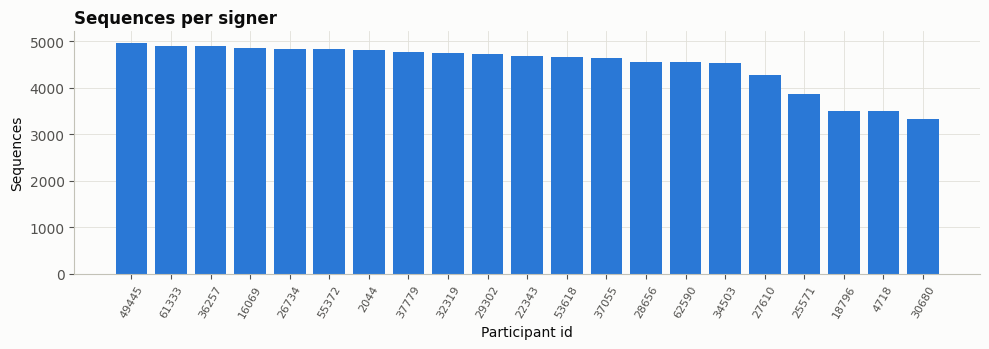

Takeaway: The busiest signer recorded 4,968 sequences and the quietest 3,338: a 1.5x gap between signers.

In [7]:
meta = pd.read_csv(DATA_DIR / "train.csv")  # All rows, whatever the FAST setting.
per_signer = meta.groupby("participant_id").size().sort_values(ascending=False)
per_sign = meta.groupby("sign").size()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(range(len(per_signer)), per_signer.values, color=BLUE, width=0.8)
ax.set_xticks(range(len(per_signer)), per_signer.index.astype(str), rotation=60, fontsize=8)
ax.set(title="Sequences per signer", xlabel="Participant id", ylabel="Sequences")
plt.tight_layout()
plt.show()
takeaway(f"The busiest signer recorded {per_signer.max():,} sequences and the quietest {per_signer.min():,}: "
         f"a {per_signer.max() / per_signer.min():.1f}x gap between signers.")

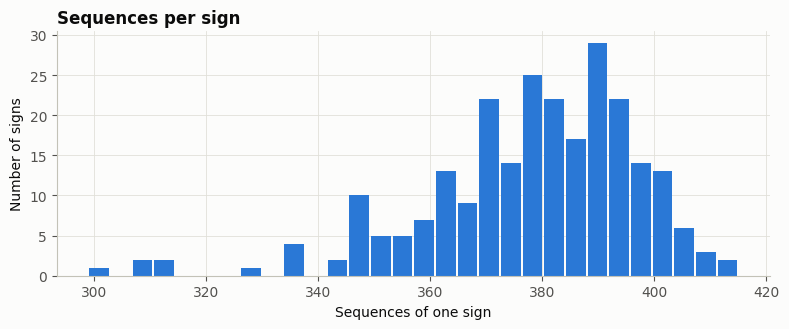

fewest: {'zipper': 299, 'vacuum': 307, 'beside': 310, 'dance': 312, 'person': 312}
most:   {'listen': 415, 'look': 414, 'shhh': 411, 'donkey': 410, 'mouse': 408}


Takeaway: Every sign has between 299 and 415 sequences (median 382), so the 250 classes are close to balanced and plain accuracy is a fair headline metric.

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(per_sign.values, bins=30, color=BLUE, rwidth=0.9)
ax.set(title="Sequences per sign", xlabel="Sequences of one sign", ylabel="Number of signs")
plt.tight_layout()
plt.show()
print("fewest:", per_sign.nsmallest(5).to_dict())
print("most:  ", per_sign.nlargest(5).to_dict())
balanced = per_sign.max() / per_sign.min() < 2
takeaway(f"Every sign has between {per_sign.min()} and {per_sign.max()} sequences (median {per_sign.median():.0f})"
         + (", so the 250 classes are close to balanced and plain accuracy is a fair headline metric." if balanced else "."))

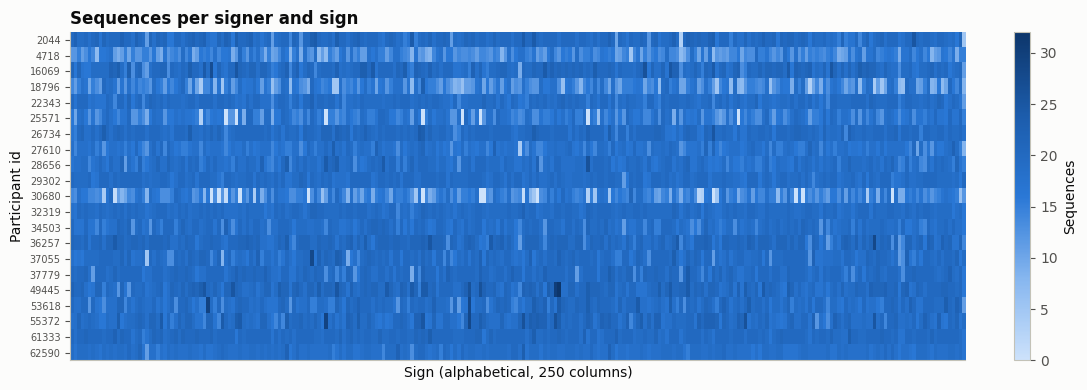

Takeaway: 19 of 21 signers recorded every sign, and a signer records a sign 19 times at the median (up to 32), so a random split puts same-signer copies of test clips in training (notebook 3).

In [9]:
coverage = meta.pivot_table(index="participant_id", columns="sign", values="sequence_id", aggfunc="count", fill_value=0)
fig, ax = plt.subplots(figsize=(11, 4))
image = ax.imshow(coverage.values, aspect="auto", cmap=BLUES, interpolation="nearest")
ax.set_yticks(range(len(coverage)), coverage.index.astype(str), fontsize=7)
ax.set_xticks([])
ax.grid(False)
ax.set(title="Sequences per signer and sign", xlabel="Sign (alphabetical, 250 columns)", ylabel="Participant id")
fig.colorbar(image, ax=ax, label="Sequences", fraction=0.03)
plt.tight_layout()
plt.show()
full = int((coverage > 0).all(axis=1).sum())
repeats = coverage.values[coverage.values > 0]
median_repeats = int(np.median(repeats))
takeaway(f"{full} of {len(coverage)} signers recorded every sign, and a signer records a sign {median_repeats} "
         f"time{'s' if median_repeats != 1 else ''} at the median (up to {repeats.max()})"
         + (", so a random split puts same-signer copies of test clips in training (notebook 3)." if median_repeats >= 2 else "."))

## 3. Sequence length

The dataset gives no frame rate. The repository behind this series assumes 30 frames per second when it needs seconds, and the plots here stay in frames.

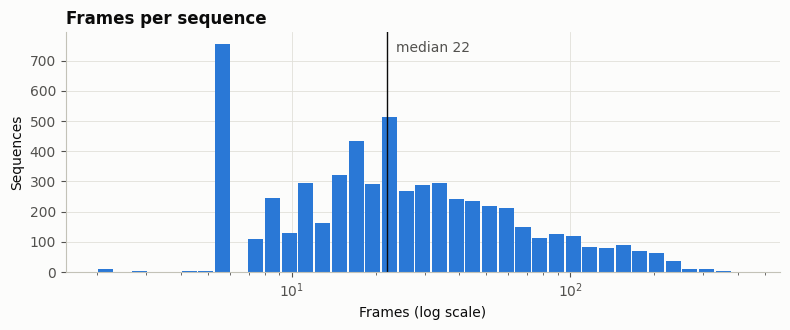

Takeaway: Half the sequences have 22 frames or fewer, the 90th percentile is 92 and the longest has 436; 8.6% run past 100 frames, which is why models resample to a fixed length.

In [10]:
lengths = stats["frames"]
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.logspace(np.log10(lengths.min()), np.log10(lengths.max()), 40)
ax.hist(lengths, bins=bins, color=BLUE, rwidth=0.9)
ax.axvline(lengths.median(), color=INK, linewidth=1)
ax.annotate(f"median {lengths.median():.0f}", (lengths.median(), ax.get_ylim()[1] * 0.92), xytext=(6, 0),
            textcoords="offset points", color=INK_2)
ax.set_xscale("log")
ax.set(title="Frames per sequence", xlabel="Frames (log scale)", ylabel="Sequences")
plt.tight_layout()
plt.show()
takeaway(f"Half the sequences have {lengths.median():.0f} frames or fewer, the 90th percentile is {lengths.quantile(0.9):.0f} "
         f"and the longest has {lengths.max()}; {(lengths > 100).mean():.1%} run past 100 frames, which is why models resample to a fixed length.")

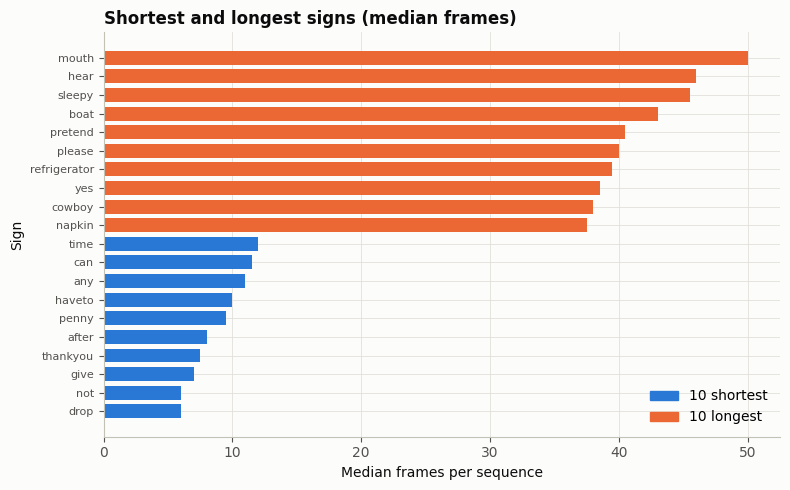

Takeaway: Median length ranges from 6 frames ('drop') to 50 ('mouth'), so the slowest sign takes 8.3 times as many frames as the fastest.

In [11]:
by_sign = stats.groupby("sign")["frames"].median().sort_values()
ends = pd.concat([by_sign.head(10), by_sign.tail(10)])
fig, ax = plt.subplots(figsize=(8, 5))
colours = [BLUE] * 10 + [ORANGE] * 10
ax.barh(range(len(ends)), ends.values, color=colours, height=0.75)
ax.set_yticks(range(len(ends)), ends.index, fontsize=8)
ax.set(title="Shortest and longest signs (median frames)", xlabel="Median frames per sequence", ylabel="Sign")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
          labels=["10 shortest", "10 longest"], loc="lower right")
plt.tight_layout()
plt.show()
takeaway(f"Median length ranges from {by_sign.min():.0f} frames ('{by_sign.index[0]}') to {by_sign.max():.0f} "
         f"('{by_sign.index[-1]}'), so the slowest sign takes {by_sign.max() / by_sign.min():.1f} times as many frames as the fastest.")

In [12]:
by_signer = stats.groupby("participant_id")["frames"].describe()[["count", "25%", "50%", "75%", "max"]].astype(int)
display(by_signer.sort_values("50%"))
takeaway(f"Per-signer median length runs from {by_signer['50%'].min()} to {by_signer['50%'].max()} frames, against "
         f"{by_sign.min():.0f} to {by_sign.max():.0f} across signs: length varies with the signer as well as the sign.")

,count,25%,50%,75%,max
participant_id,,,,,
37779,280,6,9,12,29
30680,208,6,12,21,119
25571,240,6,13,20,172
2044,288,10,15,19,40
18796,211,7,15,52,362
53618,336,10,16,40,231
62590,303,13,17,22,226
4718,209,11,21,60,135
37055,305,13,22,31,302


Takeaway: Per-signer median length runs from 9 to 55 frames, against 6 to 50 across signs: length varies with the signer as well as the sign.

## 4. Missing hands

A hand counts as present in a frame when all 21 of its points are finite.

present per frame (mean over sequences): face mesh 99.2%, both shoulders 100.0%, at least one hand 64.9%


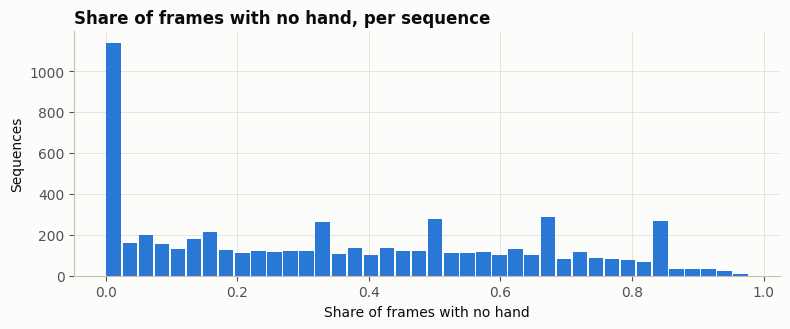

Takeaway: The median sequence has no hand in 33% of its frames, and 464 sequences (7.7%) show a hand in fewer than 3 frames, so preprocessing drops them.

In [13]:
print(f"present per frame (mean over sequences): face mesh {stats['face'].mean():.1%}, both shoulders "
      f"{stats['shoulders'].mean():.1%}, at least one hand {1 - stats['no_hand'].mean():.1%}")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(stats["no_hand"], bins=40, color=BLUE, rwidth=0.9)
ax.set(title="Share of frames with no hand, per sequence", xlabel="Share of frames with no hand", ylabel="Sequences")
plt.tight_layout()
plt.show()
few = int((stats["hand_frames"] < MIN_HAND_FRAMES).sum())
takeaway(f"The median sequence has no hand in {stats['no_hand'].median():.0%} of its frames, and {few:,} sequences "
         f"({few / len(stats):.1%}) show a hand in fewer than {MIN_HAND_FRAMES} frames, so preprocessing drops them.")

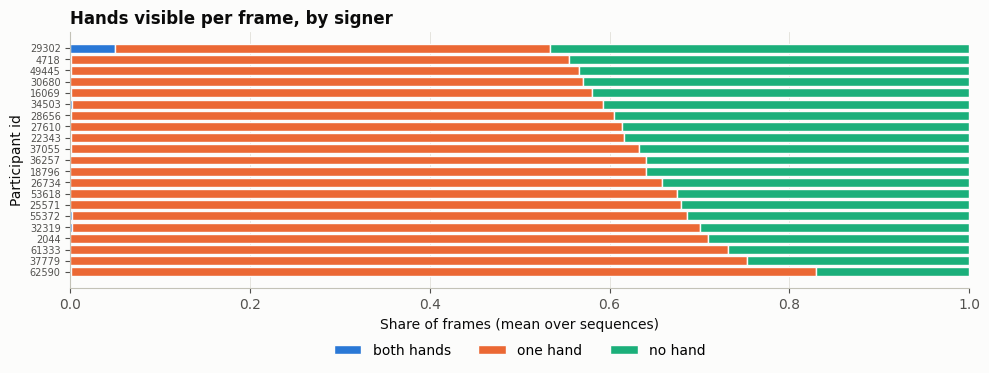

Takeaway: Frames with no hand range from 17% to 47% by signer, and both hands are visible in 0% to 5% of frames.

In [14]:
shares = stats.groupby("participant_id")[["both_hands", "no_hand"]].mean()
shares["one_hand"] = 1 - shares["both_hands"] - shares["no_hand"]
shares = shares.sort_values("no_hand")
fig, ax = plt.subplots(figsize=(10, 4))
left = np.zeros(len(shares))
for column, colour, label in (("both_hands", BLUE, "both hands"), ("one_hand", ORANGE, "one hand"), ("no_hand", AQUA, "no hand")):
    ax.barh(range(len(shares)), shares[column], left=left, color=colour, label=label, height=0.8,
            edgecolor=SURFACE, linewidth=1)
    left += shares[column].values
ax.set_yticks(range(len(shares)), shares.index.astype(str), fontsize=7)
ax.set(title="Hands visible per frame, by signer", xlabel="Share of frames (mean over sequences)", ylabel="Participant id", xlim=(0, 1))
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), ncol=3)
plt.tight_layout()
plt.show()
takeaway(f"Frames with no hand range from {shares['no_hand'].min():.0%} to {shares['no_hand'].max():.0%} by signer, "
         f"and both hands are visible in {shares['both_hands'].min():.0%} to {shares['both_hands'].max():.0%} of frames.")

In [15]:
# Cross-check with the repository's preprocessing report for the full data
# (paper/data/dataset_stats.json in the ManuVox repository: 6,945 of 94,477 sequences dropped).
print(f"this run: {few:,} of {len(stats):,} sequences have fewer than {MIN_HAND_FRAMES} hand frames ({few / len(stats):.2%})")
print("repository report, full data: 6,945 of 94,477 (7.35%)")

this run: 464 of 6,000 sequences have fewer than 3 hand frames (7.73%)
repository report, full data: 6,945 of 94,477 (7.35%)


## 5. Which hand signs

MediaPipe Holistic crops each hand from the pose, so its `left_hand` block is the hand at the pose's left wrist. Whether that is the signer's anatomical left depends on whether the recording app mirrored the selfie video, and the data does not say. What we can measure is which block holds the hand in more frames.

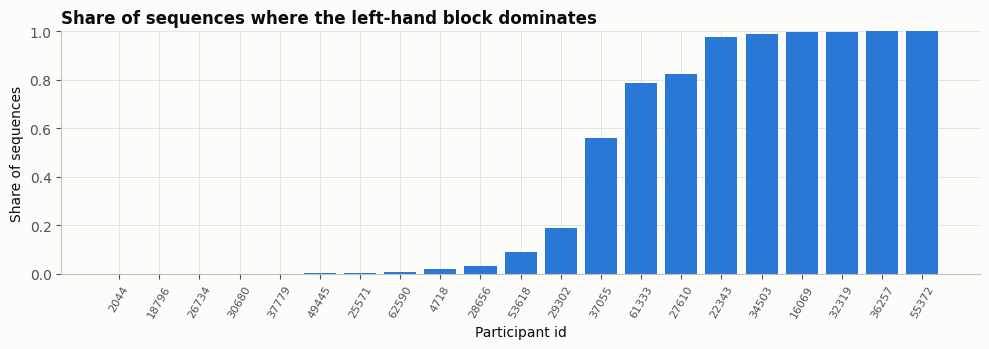

Takeaway: 11 signers use the right-hand block in over 90% of their sequences and 6 the left-hand block, with 4 in between; overall 44.2% of sequences are left-dominant (the repository's full-data report says 43.2%).

In [16]:
signing = stats[stats["hand_frames"] >= MIN_HAND_FRAMES]
left_share = signing.groupby("participant_id")["left_dominant"].mean().sort_values()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(range(len(left_share)), left_share.values, color=BLUE, width=0.8)
ax.set_xticks(range(len(left_share)), left_share.index.astype(str), rotation=60, fontsize=8)
ax.set(title="Share of sequences where the left-hand block dominates", xlabel="Participant id",
       ylabel="Share of sequences", ylim=(0, 1))
plt.tight_layout()
plt.show()
mostly_left, mostly_right = int((left_share > 0.9).sum()), int((left_share < 0.1).sum())
takeaway(f"{mostly_right} signers use the right-hand block in over 90% of their sequences and {mostly_left} the left-hand block, "
         f"with {len(left_share) - mostly_left - mostly_right} in between; overall {signing['left_dominant'].mean():.1%} of sequences "
         "are left-dominant (the repository's full-data report says 43.2%).")

Handedness is a property of the signer here, so a model that never sees left-dominant input would fail on several whole signers. The preprocessing in this series mirrors every left-dominant sequence (x becomes 1 - x and the left and right landmarks swap), so the dominant hand always sits in the right-hand block. Notebook 2 shows what happens when a live pipeline puts the hands in the wrong blocks.

## 6. Signing space and body proportions

The next plot places the dominant hand's wrist relative to the body, in shoulder widths from the shoulder midpoint, after the mirroring above. Up to 8 frames per sequence are sampled.

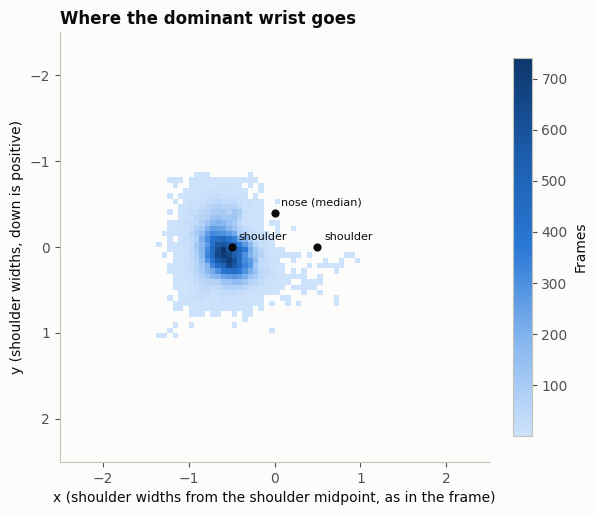

Takeaway: 90% of sampled dominant-wrist positions lie within 0.87 shoulder widths of the point halfway between the shoulders and the nose, and 99% within 1.10 (at the median the nose sits 0.40 shoulder widths above the shoulder line), so the signing space is a small region around the chest and face.

In [17]:
nose_y = float(np.nanmedian(stats["nose_y"]))
fig, ax = plt.subplots(figsize=(6, 5.4))
counts, xedges, yedges, image = ax.hist2d(wrists[:, 0], wrists[:, 1], bins=80, range=[[-2.5, 2.5], [-2.5, 2.5]],
                                          cmap=BLUES, cmin=1)
ax.scatter([-0.5, 0.5, 0], [0, 0, nose_y], color=INK, s=24, zorder=3)
for x, y, label in ((-0.5, 0, "shoulder"), (0.5, 0, "shoulder"), (0, nose_y, "nose (median)")):
    ax.annotate(label, (x, y), xytext=(5, 5), textcoords="offset points", color=INK, fontsize=8)
ax.invert_yaxis()
ax.set_aspect("equal")
ax.grid(False)
ax.set(title="Where the dominant wrist goes", xlabel="x (shoulder widths from the shoulder midpoint, as in the frame)",
       ylabel="y (shoulder widths, down is positive)")
fig.colorbar(image, ax=ax, label="Frames", fraction=0.04)
plt.tight_layout()
plt.show()
reach = np.hypot(wrists[:, 0], wrists[:, 1] - nose_y / 2)  # Distance from halfway between shoulders and nose.
r90, r99 = np.quantile(reach, [0.9, 0.99])
takeaway(f"90% of sampled dominant-wrist positions lie within {r90:.2f} shoulder widths of the point halfway between the "
         f"shoulders and the nose, and 99% within {r99:.2f} (at the median the nose sits {abs(nose_y):.2f} shoulder widths "
         "above the shoulder line), so the signing space is a small region around the chest and face.")

The body ratio r is the vertical distance from the nose to the shoulder line divided by the shoulder width, both in frame-fraction units. For one person it changes with the camera's aspect ratio, because x is divided by the frame width and y by the frame height.

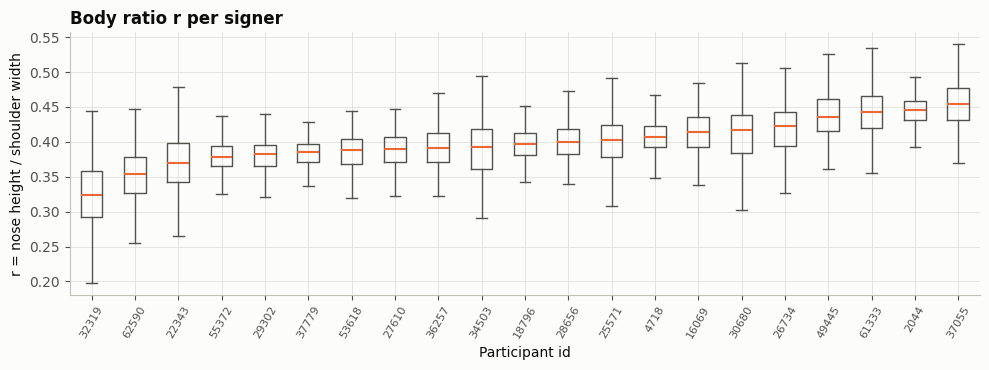

Takeaway: The median r is 0.40 (10th to 90th percentile 0.34 to 0.46); a 16:9 webcam would stretch y relative to x for every signer at once, an effect notebook 2 measures.

In [18]:
ratio = stats.dropna(subset=["body_ratio"])
order = ratio.groupby("participant_id")["body_ratio"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.boxplot([ratio.loc[ratio["participant_id"] == p, "body_ratio"] for p in order], showfliers=False,
           medianprops={"color": ORANGE, "linewidth": 1.5}, boxprops={"color": INK_2}, whiskerprops={"color": INK_2},
           capprops={"color": INK_2})
ax.set_xticks(range(1, len(order) + 1), order.astype(str), rotation=60, fontsize=8)
ax.set(title="Body ratio r per signer", xlabel="Participant id", ylabel="r = nose height / shoulder width")
plt.tight_layout()
plt.show()
q = ratio["body_ratio"].quantile([0.1, 0.5, 0.9])
takeaway(f"The median r is {q[0.5]:.2f} (10th to 90th percentile {q[0.1]:.2f} to {q[0.9]:.2f}); a 16:9 webcam would stretch y "
         "relative to x for every signer at once, an effect notebook 2 measures.")

## 7. Skeleton animations

Each panel shows one real sequence: both hands and the arms and shoulders from the pose, drawn in frame coordinates. The face mesh is left out on purpose. Points use the 0.72 width-to-height ratio that the ManuVox repository estimates for these videos (`features_spec.json`), so the proportions look natural.

In [19]:
HAND_EDGES = [(0, 1), (1, 2), (2, 3), (3, 4), (0, 5), (5, 6), (6, 7), (7, 8), (5, 9), (9, 10), (10, 11), (11, 12),
              (9, 13), (13, 14), (14, 15), (15, 16), (13, 17), (17, 18), (18, 19), (19, 20), (0, 17)]
ARM_EDGES = [(11, 12), (11, 13), (13, 15), (12, 14), (14, 16)]  # Pose indices.
WIDTH_OVER_HEIGHT = 0.723  # Effective aspect of the videos, from the repository's features_spec.json.
GIF_FRAMES = 40  # Every animation is resampled to this many frames so the panels stay in step.


class Skeleton:
    """Line artists for one skeleton on one axis; ``update`` moves them to a (59, 2) frame."""

    def __init__(self, ax):
        self.hands = [[ax.plot([], [], color=c, linewidth=1.6)[0] for _ in HAND_EDGES] for c in (ORANGE, BLUE)]
        self.arms = [ax.plot([], [], color=MUTED, linewidth=2.2)[0] for _ in ARM_EDGES]
        self.nose = ax.plot([], [], "o", color=MUTED, markersize=5)[0]

    def update(self, frame):
        for lines, block in zip(self.hands, (LEFT, RIGHT)):
            hand = frame[block]
            for line, (a, b) in zip(lines, HAND_EDGES):
                line.set_data(hand[[a, b], 0], hand[[a, b], 1])
        for line, (a, b) in zip(self.arms, ARM_EDGES):
            line.set_data(frame[[42 + a, 42 + b], 0], frame[[42 + a, 42 + b], 1])
        self.nose.set_data(frame[[NOSE], 0], frame[[NOSE], 1])
        return [*self.hands[0], *self.hands[1], *self.arms, self.nose]


def frame_axes(ax, xy):
    """Fit the axis to a sequence's points, image style (y down), with the video's aspect."""
    pts = xy.reshape(-1, 2)
    pts = pts[np.isfinite(pts).all(axis=1)]
    (x0, y0), (x1, y1) = pts.min(axis=0), pts.max(axis=0)
    pad = 0.08 * max(x1 - x0, y1 - y0)
    ax.set_xlim(x0 - pad, x1 + pad)
    ax.set_ylim(y1 + pad, y0 - pad)
    ax.set_aspect(1 / WIDTH_OVER_HEIGHT)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)


def pick_sequence(sign):
    """A clear example of ``sign``: right-dominant, shoulders always visible, the most hand frames."""
    rows = stats[(stats["sign"] == sign) & ~stats["left_dominant"] & (stats["shoulders"] == 1)]
    rows = rows if len(rows) else stats[stats["sign"] == sign]
    return rows.sort_values(["hand_frames", "sequence_id"], ascending=[False, True]).iloc[0]

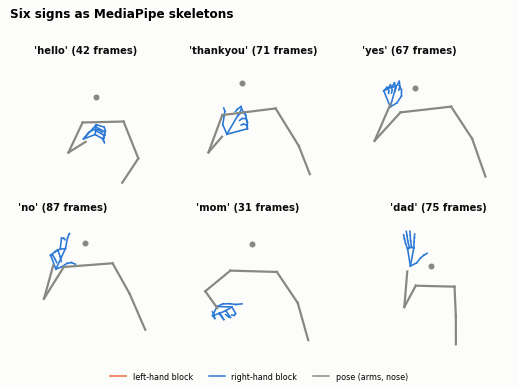

six_signs.gif: 438 kB


In [20]:
from matplotlib.animation import FuncAnimation, PillowWriter

GIF_SIGNS = ["hello", "thankyou", "yes", "no", "mom", "dad"]
examples = {sign: pick_sequence(sign) for sign in GIF_SIGNS}
sequences = {}
for sign, row in examples.items():
    xy = read_xy(DATA_DIR / row["path"])
    keep = hand_presence(xy).any(axis=1)  # Start and end where a hand is visible.
    first, last = np.flatnonzero(keep)[[0, -1]]
    xy = xy[first : last + 1]
    sequences[sign] = xy[np.linspace(0, len(xy) - 1, GIF_FRAMES).round().astype(int)]

fig, axes = plt.subplots(2, 3, figsize=(7.2, 5.4))
skeletons = []
for ax, (sign, xy) in zip(axes.flat, sequences.items()):
    frame_axes(ax, xy)
    ax.set_title(f"'{sign}' ({examples[sign]['frames']} frames)", fontsize=10)
    skeletons.append(Skeleton(ax))
fig.legend(handles=[plt.Line2D([], [], color=ORANGE), plt.Line2D([], [], color=BLUE), plt.Line2D([], [], color=MUTED)],
           labels=["left-hand block", "right-hand block", "pose (arms, nose)"], loc="lower center", ncol=3, fontsize=8)
fig.suptitle("Six signs as MediaPipe skeletons", fontweight="bold", x=0.02, ha="left")
plt.tight_layout(rect=(0, 0.06, 1, 0.97))


def draw(i):
    return [artist for sk, xy in zip(skeletons, sequences.values()) for artist in sk.update(xy[i])]


gif_path = WORK_DIR / "six_signs.gif"
FuncAnimation(fig, draw, frames=GIF_FRAMES, blit=False).save(gif_path, writer=PillowWriter(fps=10), dpi=72)
plt.close(fig)
display(Image(filename=str(gif_path)))
print(f"{gif_path.name}: {gif_path.stat().st_size / 1e3:.0f} kB")

In [21]:
def thumb_height(sign):
    """Median height of the dominant thumb tip above (-) or below (+) the nose, in shoulder widths."""
    xy = sequences[sign]
    body = mirror(xy) if examples[sign]["left_dominant"] else xy
    centre, scale = normalisation(body)
    return float(np.nanmedian((body[:, RIGHT.start + 4, 1] - body[:, NOSE, 1]) / scale))


heights = pd.Series({sign: thumb_height(sign) for sign in GIF_SIGNS}, name="thumb below nose (shoulder widths)")
display(heights.round(2).to_frame().T)
where = lambda v: f"{abs(v):.2f} shoulder widths {'below' if v > 0 else 'above'} the nose"  # noqa: E731
takeaway(f"'mom' and 'dad' share a handshape; in these examples the thumb sits {where(heights['mom'])} for 'mom' and "
         f"{where(heights['dad'])} for 'dad', so the hand's height relative to the face tells them apart.")

,hello,thankyou,yes,no,mom,dad
thumb below nose (shoulder widths),0.37,0.23,0.01,-0.01,0.18,-0.24


Takeaway: 'mom' and 'dad' share a handshape; in these examples the thumb sits 0.18 shoulder widths below the nose for 'mom' and 0.24 shoulder widths above the nose for 'dad', so the hand's height relative to the face tells them apart.

A filmstrip of one sequence shows the same motion frame by frame, using 8 of the frames where MediaPipe found a hand. This figure is also the notebook's cover image.

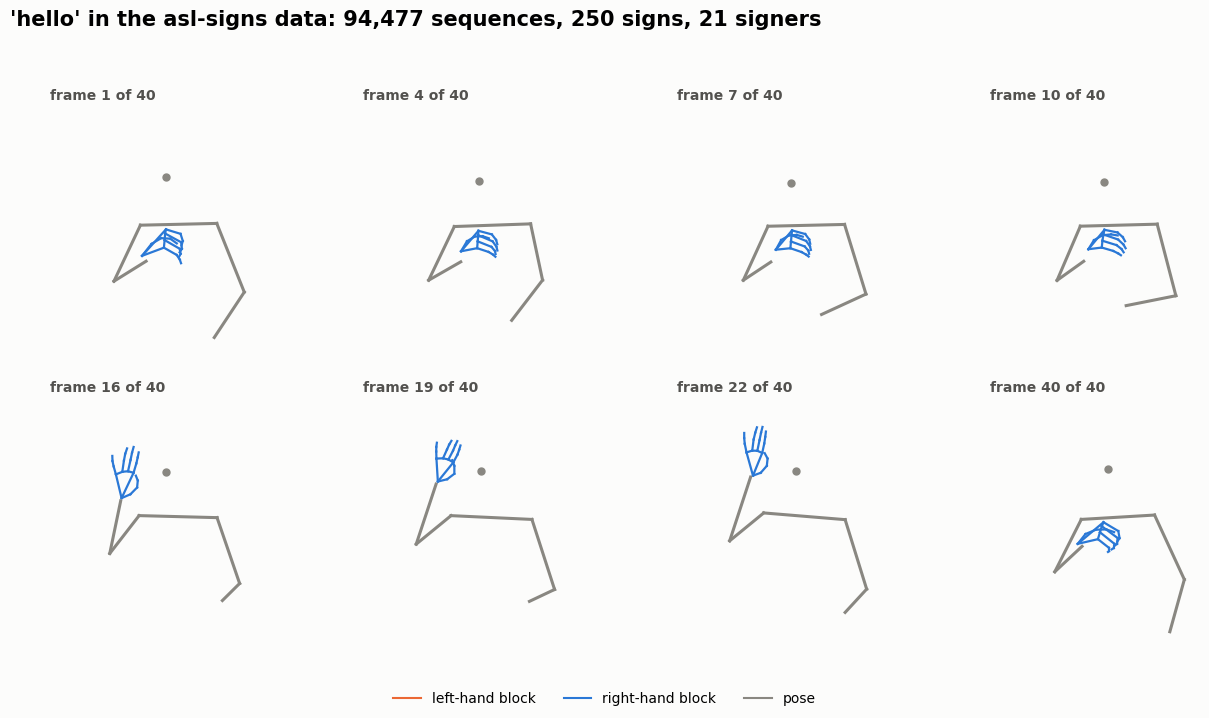

Takeaway: Over the clip the right-hand block holds a hand in 55% of frames and the left-hand block in 0%, so this 'hello' is signed with one hand (42 frames in the original file).

In [22]:
tracked = np.flatnonzero(hand_presence(sequences["hello"]).any(axis=1))  # Frames with a hand.
picked = tracked[np.linspace(0, len(tracked) - 1, 8).round().astype(int)]
fig, axes = plt.subplots(2, 4, figsize=(12.8, 7.2))
for ax, i in zip(axes.flat, picked):
    frame_axes(ax, sequences["hello"])
    Skeleton(ax).update(sequences["hello"][i])
    ax.set_title(f"frame {i + 1} of {GIF_FRAMES}", fontsize=10, color=INK_2)
fig.suptitle(f"'hello' in the asl-signs data: {len(meta):,} sequences, {meta['sign'].nunique()} signs, "
             f"{meta['participant_id'].nunique()} signers", fontweight="bold", x=0.02, ha="left", fontsize=15)
fig.legend(handles=[plt.Line2D([], [], color=ORANGE), plt.Line2D([], [], color=BLUE), plt.Line2D([], [], color=MUTED)],
           labels=["left-hand block", "right-hand block", "pose"], loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.06, 1, 0.94))
save_cover(fig)
plt.show()
shown = hand_presence(sequences["hello"]).mean(axis=0)
takeaway(f"Over the clip the right-hand block holds a hand in {shown[1]:.0%} of frames and the left-hand block in {shown[0]:.0%}, "
         f"so this 'hello' is signed with one hand ({examples['hello']['frames']} frames in the original file).")

## 8. What we found

In [23]:
display(Markdown(
    f"The data lists {len(meta):,} sequences of {meta['sign'].nunique()} signs from {meta['participant_id'].nunique()} signers, "
    f"with {per_sign.min()} to {per_sign.max()} sequences per sign, {per_signer.min():,} to {per_signer.max():,} per signer, and "
    f"each sign recorded {median_repeats} times per signer at the median, the reason notebook 3 splits by signer. "
    + (f"The per-file figures that follow come from the {len(stats):,} files this FAST run read. " if FAST else "")
    + f"Sequences are short, with a median of {lengths.median():.0f} frames, and the median sequence has no hand in "
    f"{stats['no_hand'].median():.0%} of its frames; {few / len(stats):.1%} show a hand in fewer than {MIN_HAND_FRAMES} frames. "
    f"{mostly_right} signers use the right-hand block in over 90% of their sequences and {mostly_left} the left-hand block, "
    f"which is why the series mirrors left-dominant sequences before training."
))

The data lists 94,477 sequences of 250 signs from 21 signers, with 299 to 415 sequences per sign, 3,338 to 4,968 per signer, and each sign recorded 19 times per signer at the median, the reason notebook 3 splits by signer. The per-file figures that follow come from the 6,000 files this FAST run read. Sequences are short, with a median of 22 frames, and the median sequence has no hand in 33% of its frames; 7.7% show a hand in fewer than 3 frames. 11 signers use the right-hand block in over 90% of their sequences and 6 the left-hand block, which is why the series mirrors left-dominant sequences before training.

### Limitations

- The frame rate is unknown, so durations are in frames. Lengths may differ between recording devices for the same signing speed.
- Whether the `left_hand` block is the anatomical left hand depends on video mirroring that the data does not record.
- The body ratio mixes anatomy, camera distance and aspect ratio; this notebook cannot separate them.
- The skeleton examples are picked by a rule (most hand frames), so they are cleaner than a typical sequence.

### Ideas to try

- Cluster signers by their wrist heatmaps and check whether the clusters match recording setups.
- Measure tracking jitter: frame-to-frame wrist speed when the hand should be still at the start of a clip.
- Use the face mesh, which this series drops, to see whether mouth shapes separate signs that share a handshape.

### The series

- [2. The hand-swap bug: measuring train-serve skew in MediaPipe sign recognition](https://www.kaggle.com/code/swapnilshukla007/the-hand-swap-bug-train-serve-skew-in-asl-models)
- [3. Why random splits overstate sign recognition accuracy](https://www.kaggle.com/code/swapnilshukla007/why-random-splits-overstate-sign-accuracy)
- [4. A CNN + Transformer hybrid for isolated sign recognition in PyTorch](https://www.kaggle.com/code/swapnilshukla007/cnn-transformer-hybrid-for-isolated-asl-signs)
- [5. From PyTorch to the browser: ONNX export, FP16/INT8 quantization and temperature calibration](https://www.kaggle.com/code/swapnilshukla007/pytorch-to-browser-onnx-fp16-int8-calibration)

If this helped, an upvote helps other people find it, and feedback in the comments is welcome.